# Comparative Analysis: Adaptive MPC (with Profile Likelihood Calculation ) vs unadapted MPC and benchmark (MPC with plant model)
This notebook evaluates and compares the results from benchmark MPC, nominal MPC, and adaptive MPC with online Profile Likelihood. 
The initial parameter values are loaded from `Set_up_general.py` (via `initial_para`), which are defined in log10 space. 

It generates publication-ready comparison figures and performance metrics. 


In [1]:
# add path '
from pathlib import Path 
import sys 

# Dynamically resolve project root containing solver_config.py 
project_root = Path.cwd().resolve() 
while project_root != project_root.parent and not (project_root / "solver_config.py").exists(): 
    project_root = project_root.parent 

if str(project_root) not in sys.path: 
    sys.path.insert(0, str(project_root)) 

# set up 
from Set_up_general import * # for all relevant other files - general setup + figures 


CasADi - 2026-10-20 11:04:11 WARNING("The options 't0', 'tf', 'grid' and 'output_t0' have been deprecated.
The same functionality is provided by providing additional input arguments to the 'integrator' function, in particular:
 * Call integrator(..., t0, tf, options) for a single output time, or
 * Call integrator(..., t0, grid, options) for multiple grid points.
The legacy 'output_t0' option can be emulated by including or excluding 't0' in 'grid'.
Backwards compatibility is provided in this release only.") [.../casadi/core/integrator.cpp:692]


load data MPC

In [2]:
# Load comparison results from dataset_PL.npz
data = np.load("dataset_MPC.npz")

N0 = data['N0']
t = data['t']
n_sets = initial_para.shape[1]

results_MPC = {}
for i in range(n_sets):
    results_MPC[i] = {
        'p_start_log': data[f'p_start_log_{i}'],
        'Y_adapted': data[f'Y_adapted_{i}'],
        'U_applied': data[f'U_applied_{i}'],
        'X_real_tk': data[f'X_real_tk_{i}'],
        'Broken_mpc': data[f'Broken_mpc_{i}'],
        't_mean': data[f't_mean_{i}'],
        't_matrix': data[f't_matrix_{i}'] if f't_matrix_{i}' in data else None,
    }


In [3]:
# Load comparison results from dataset_PL.npz
data = np.load("dataset_MPC_benchmark.npz")

N0 = data['N0']
t = data['t']

results_MPC_benchmark = {
    'p_start_log': data[f'p_start_log'],
    'Y_adapted': data[f'Y_adapted'],
    'U_applied': data[f'U_applied'],
    'X_real_tk': data[f'X_real_tk'],
    'Broken_mpc': data[f'Broken_mpc'],
    't_mean': data[f't_mean'] if 't_mean' in data else None,
    't_matrix': data[f't_matrix'] if 't_matrix' in data else None,
}


load data MHE and MPC

In [4]:
# Load comparison results from dataset_MPC_MHE_PL.npz, falling back to dataset_PL.npz or dataset_MHE_MPC.npz if not available
import os
dataset_file = "dataset_MPC_MHE_PL.npz"
data = np.load(dataset_file)
print(f"Loaded evaluation data from: {dataset_file}")

N0 = data['N0']
t = data['t']
n_sets = initial_para.shape[1]

results_MHE_MPC_PL = {}
for i in range(n_sets):
    results_MHE_MPC_PL[i] = {
        'p_start_log': data[f'p_start_log_{i}'],
        'Y_adapted': data[f'Y_adapted_{i}'],
        'U_applied': data[f'U_applied_{i}'],
        'Para_MHE': data[f'Para_MHE_{i}'],
        'X_real_tk': data[f'X_real_tk_{i}'],
        'Broken_mhe': data[f'Broken_mhe_{i}'],
        'Broken_mpc': data[f'Broken_mpc_{i}'],
        't_mean': data[f't_mean_{i}'],
        't_matrix': data[f't_matrix_{i}'] if f't_matrix_{i}' in data else None} 

    results_MHE_MPC_PL[i].update({
            'Obj_tk': data[f'Obj_tk_{i}'],
            'Para_PL': data[f'Para_PL_{i}'],
            'Broken_PL_tk': data[f'Broken_PL_tk_{i}']})



Loaded evaluation data from: dataset_MPC_MHE_PL.npz


Plot results

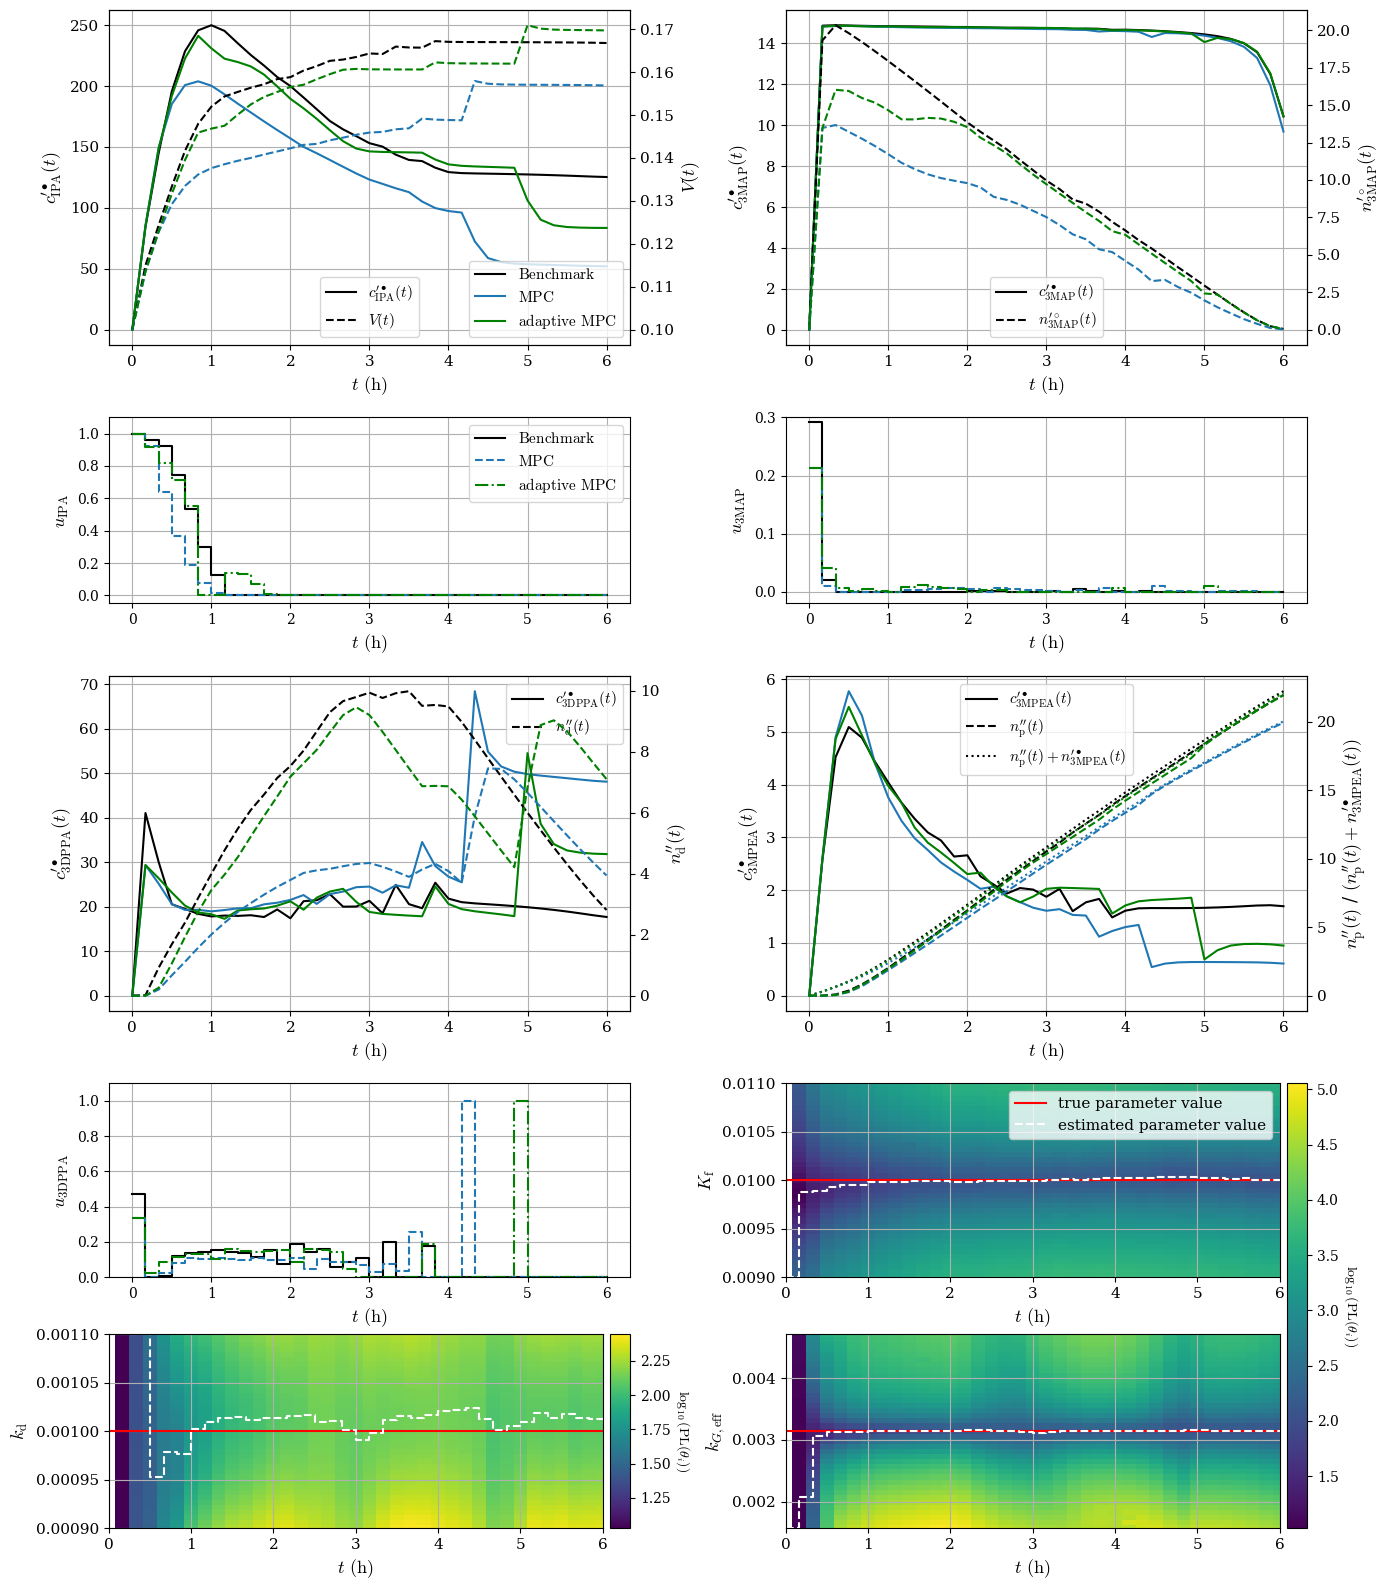

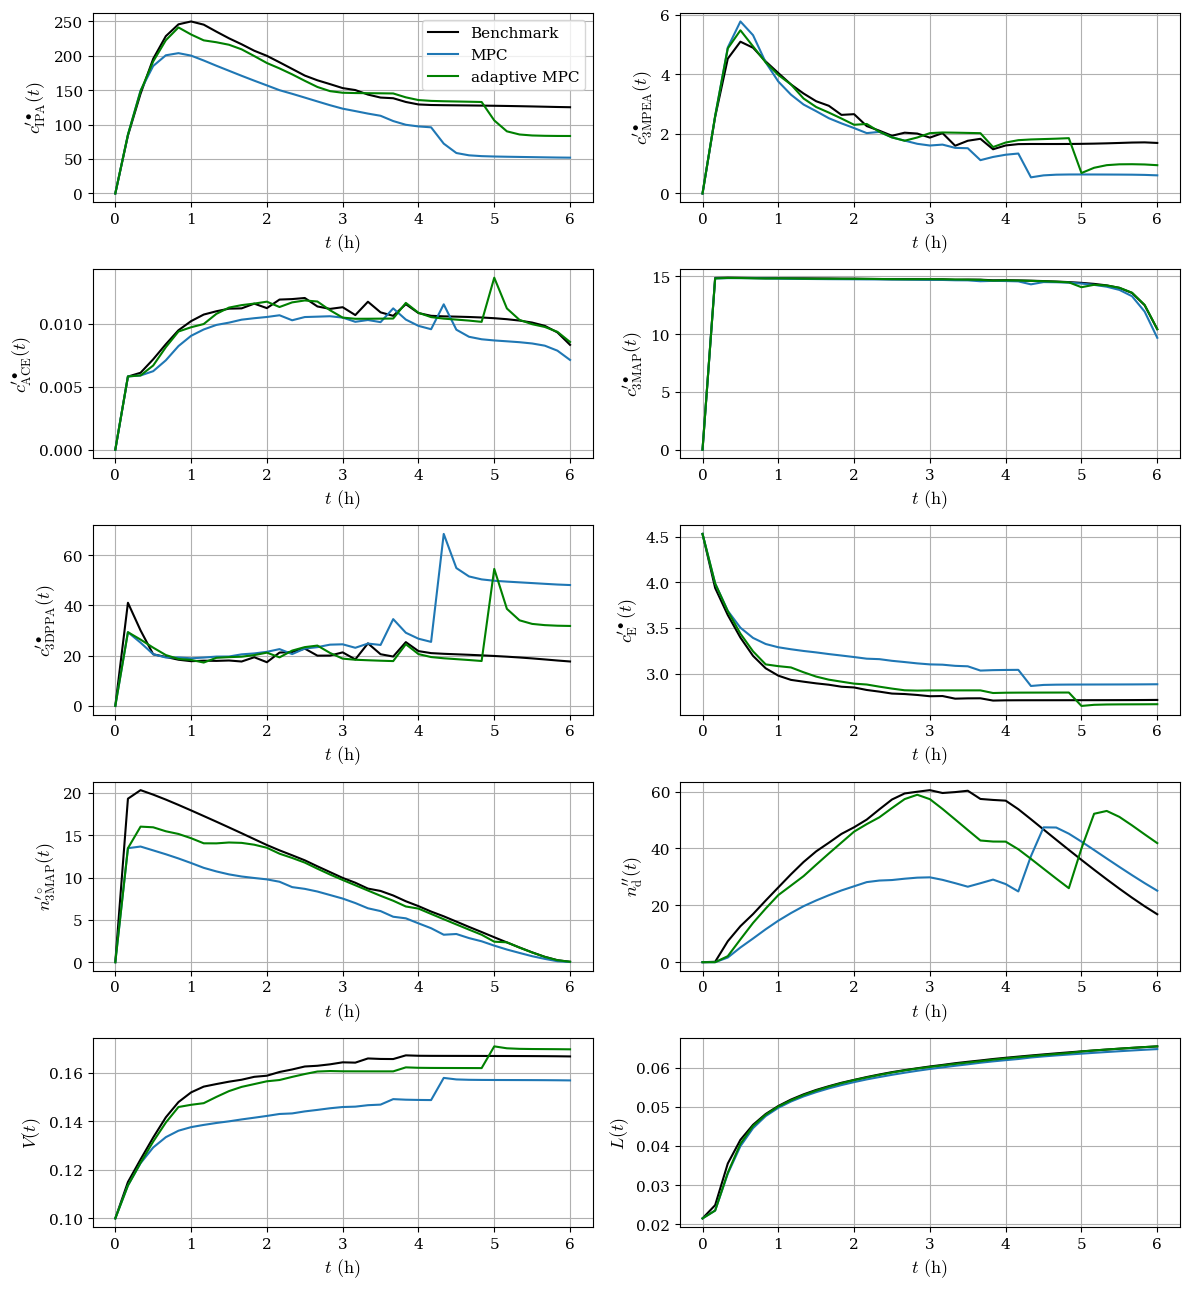

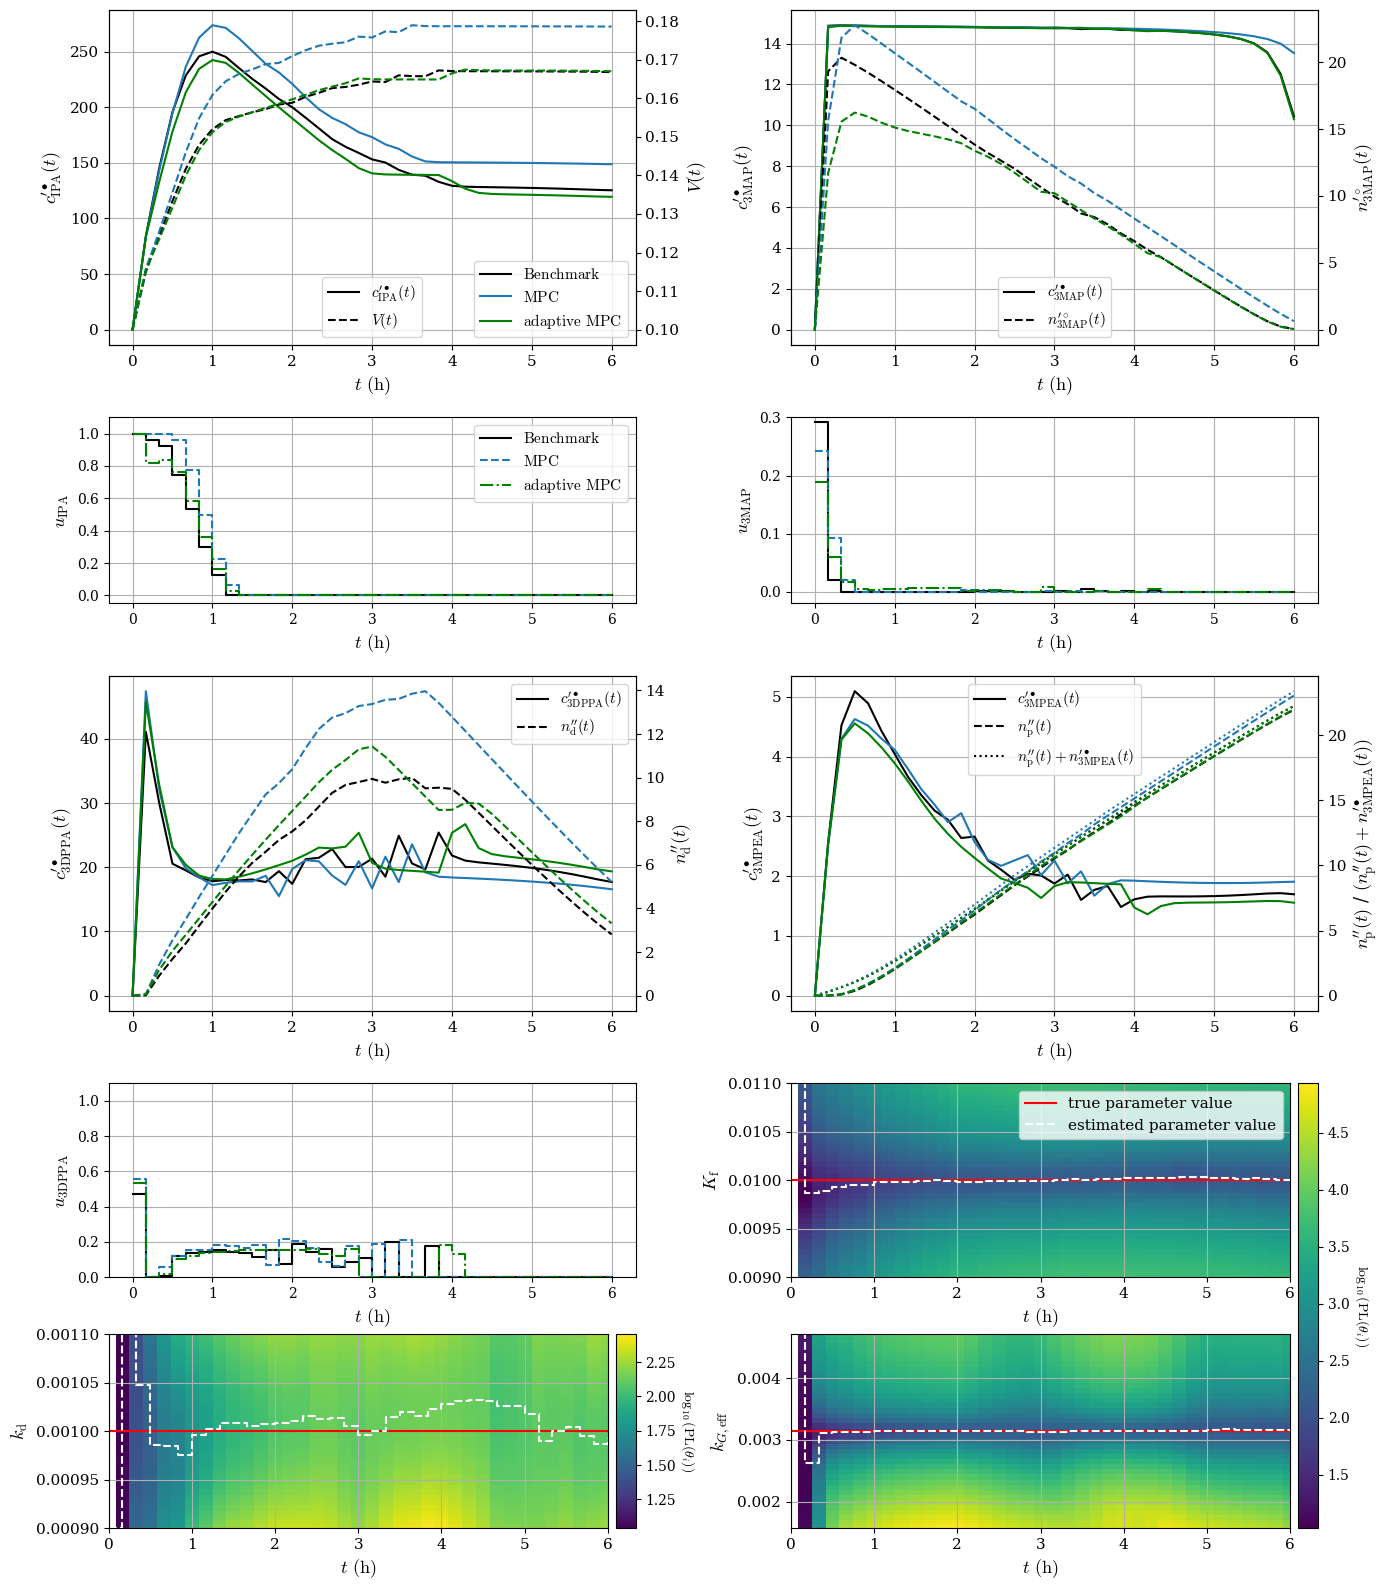

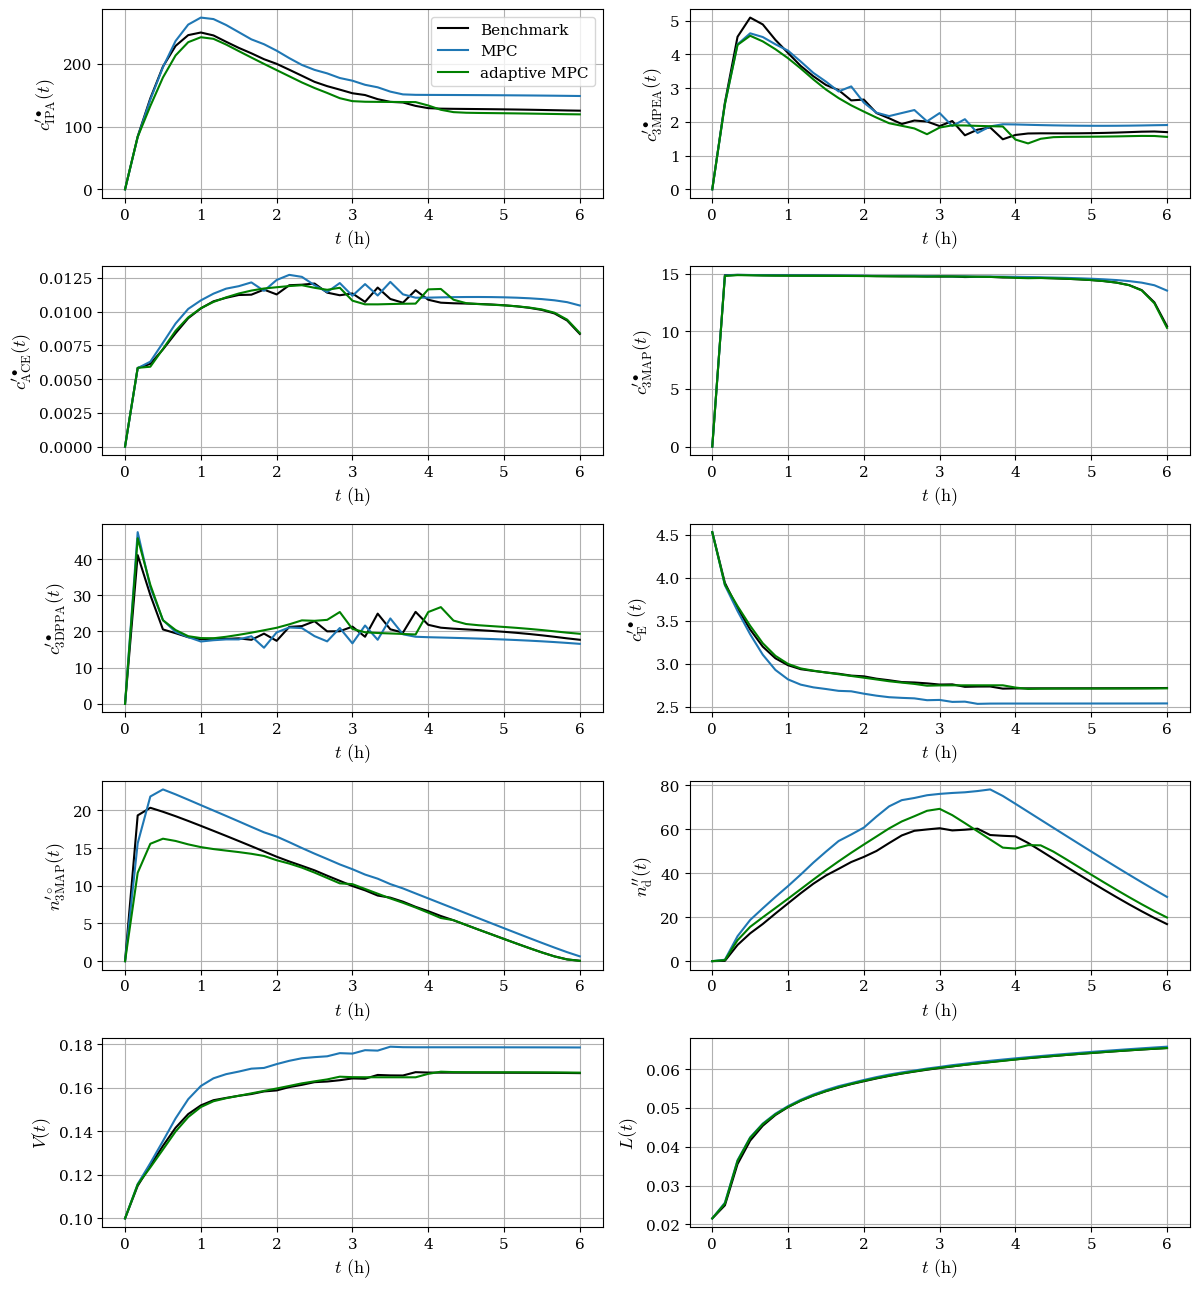

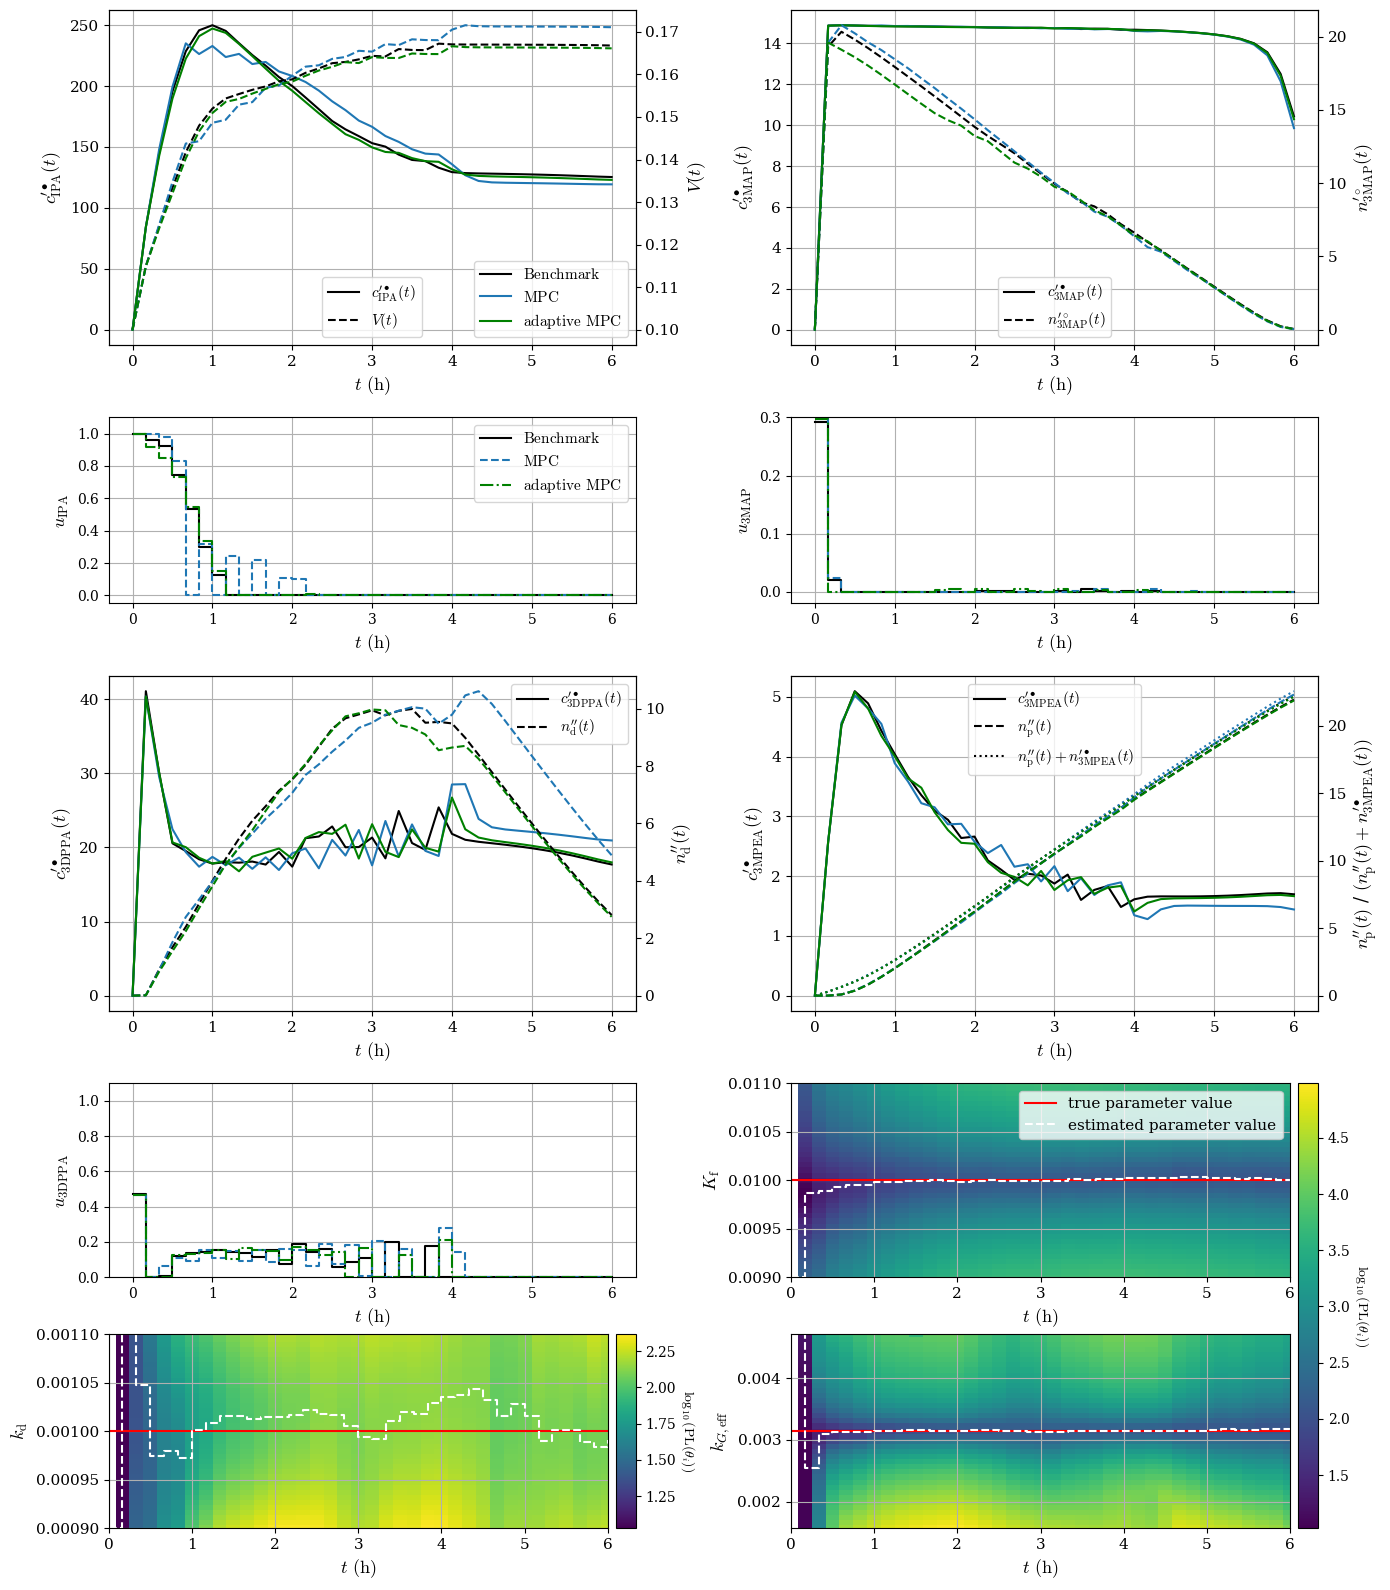

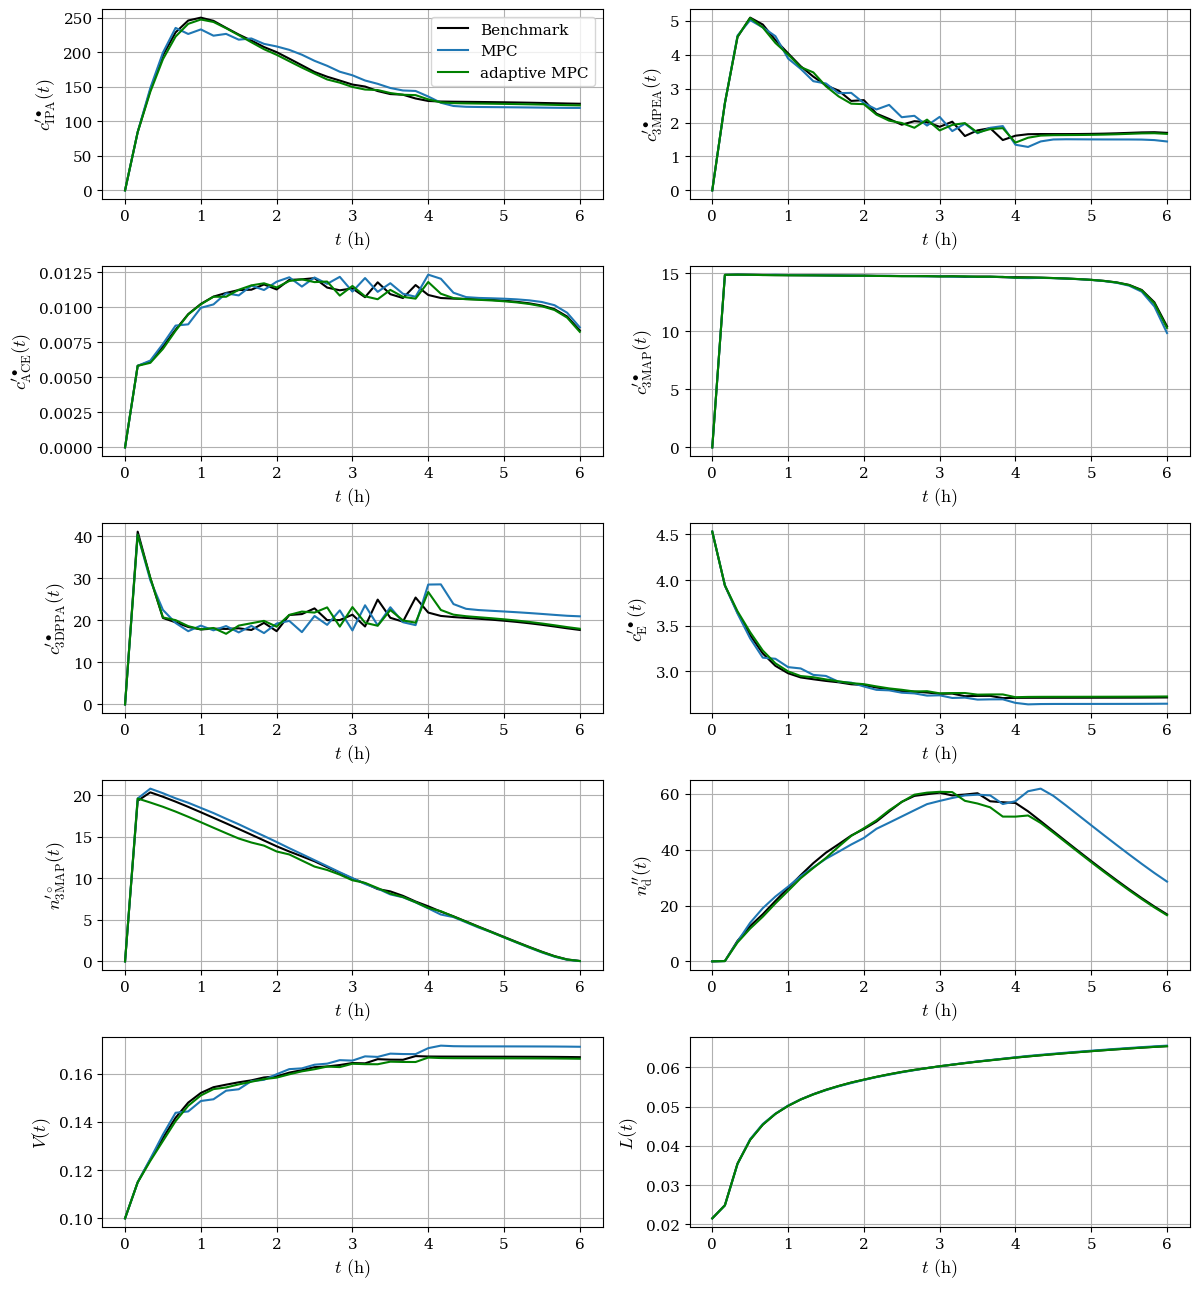

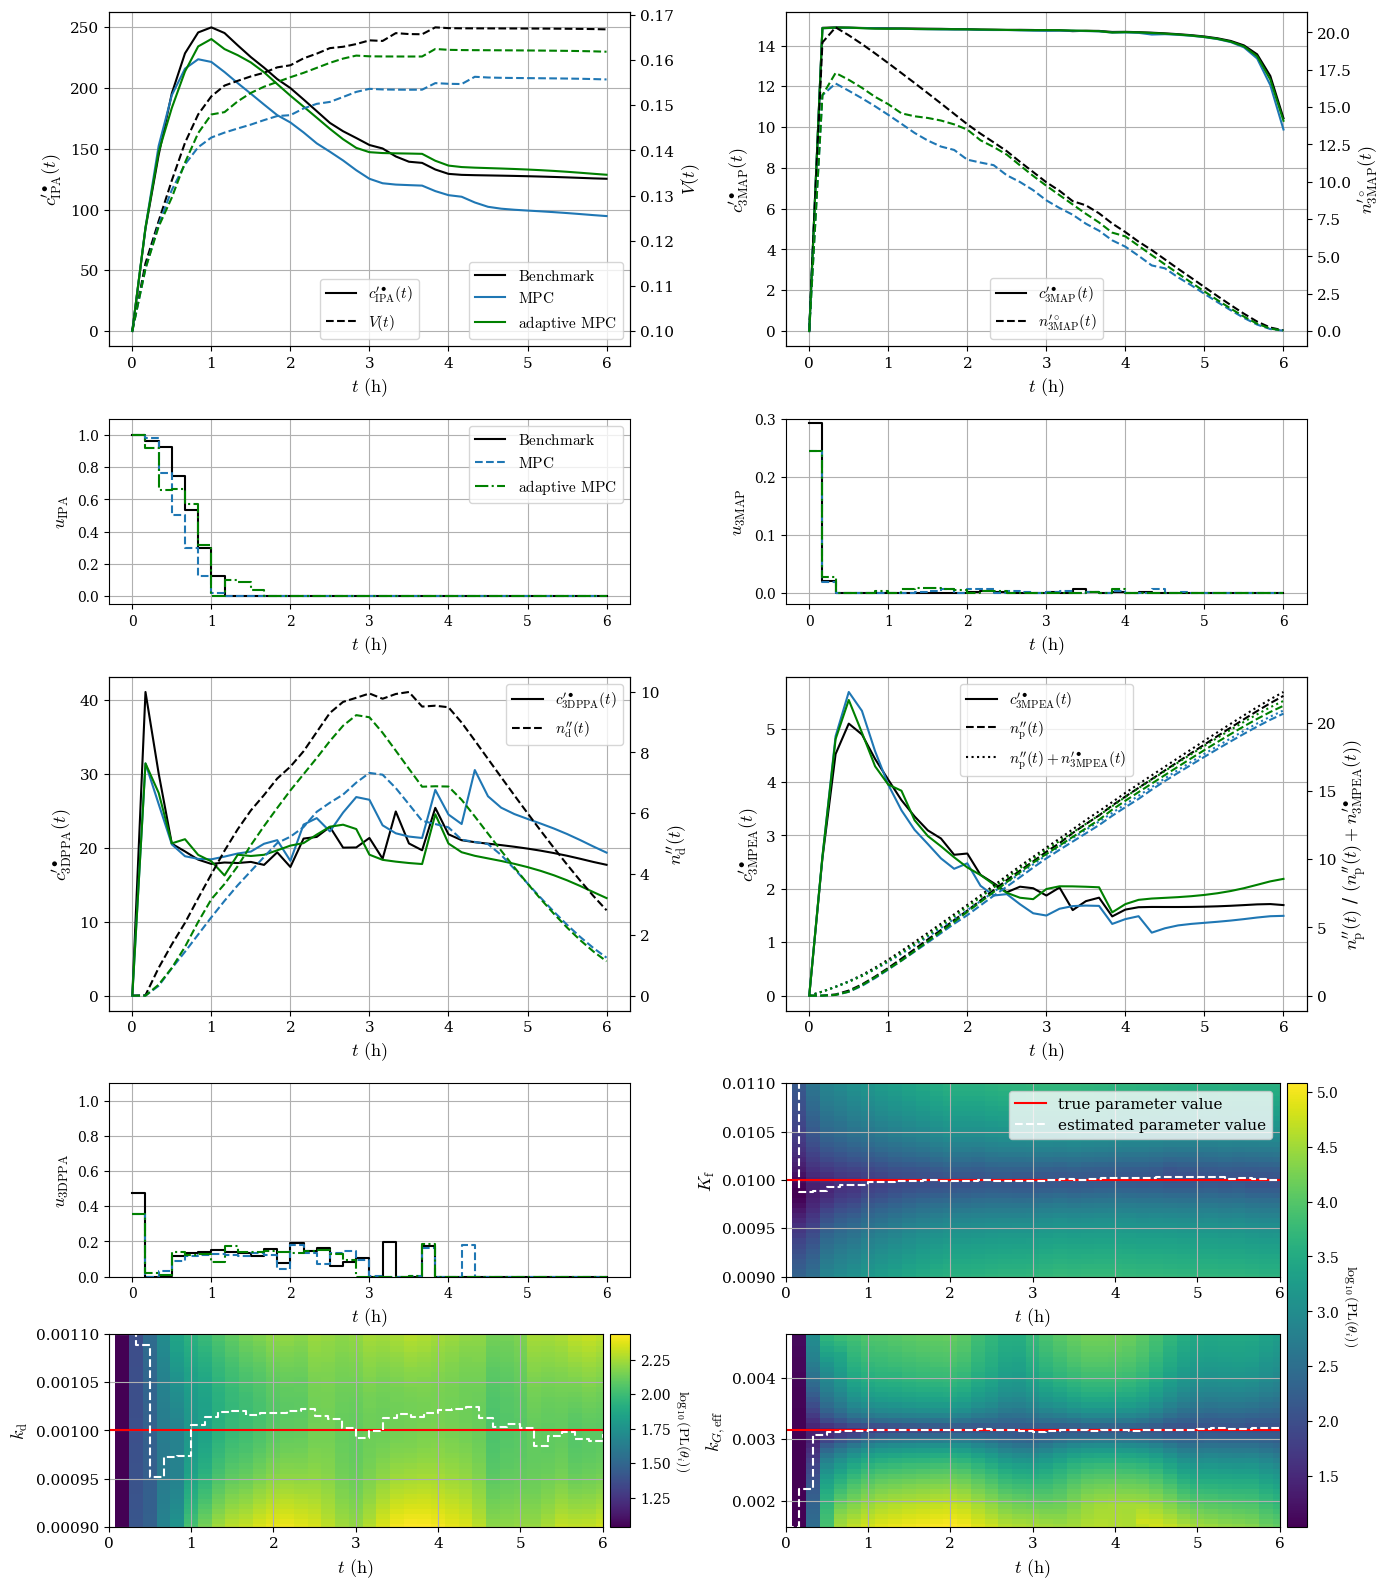

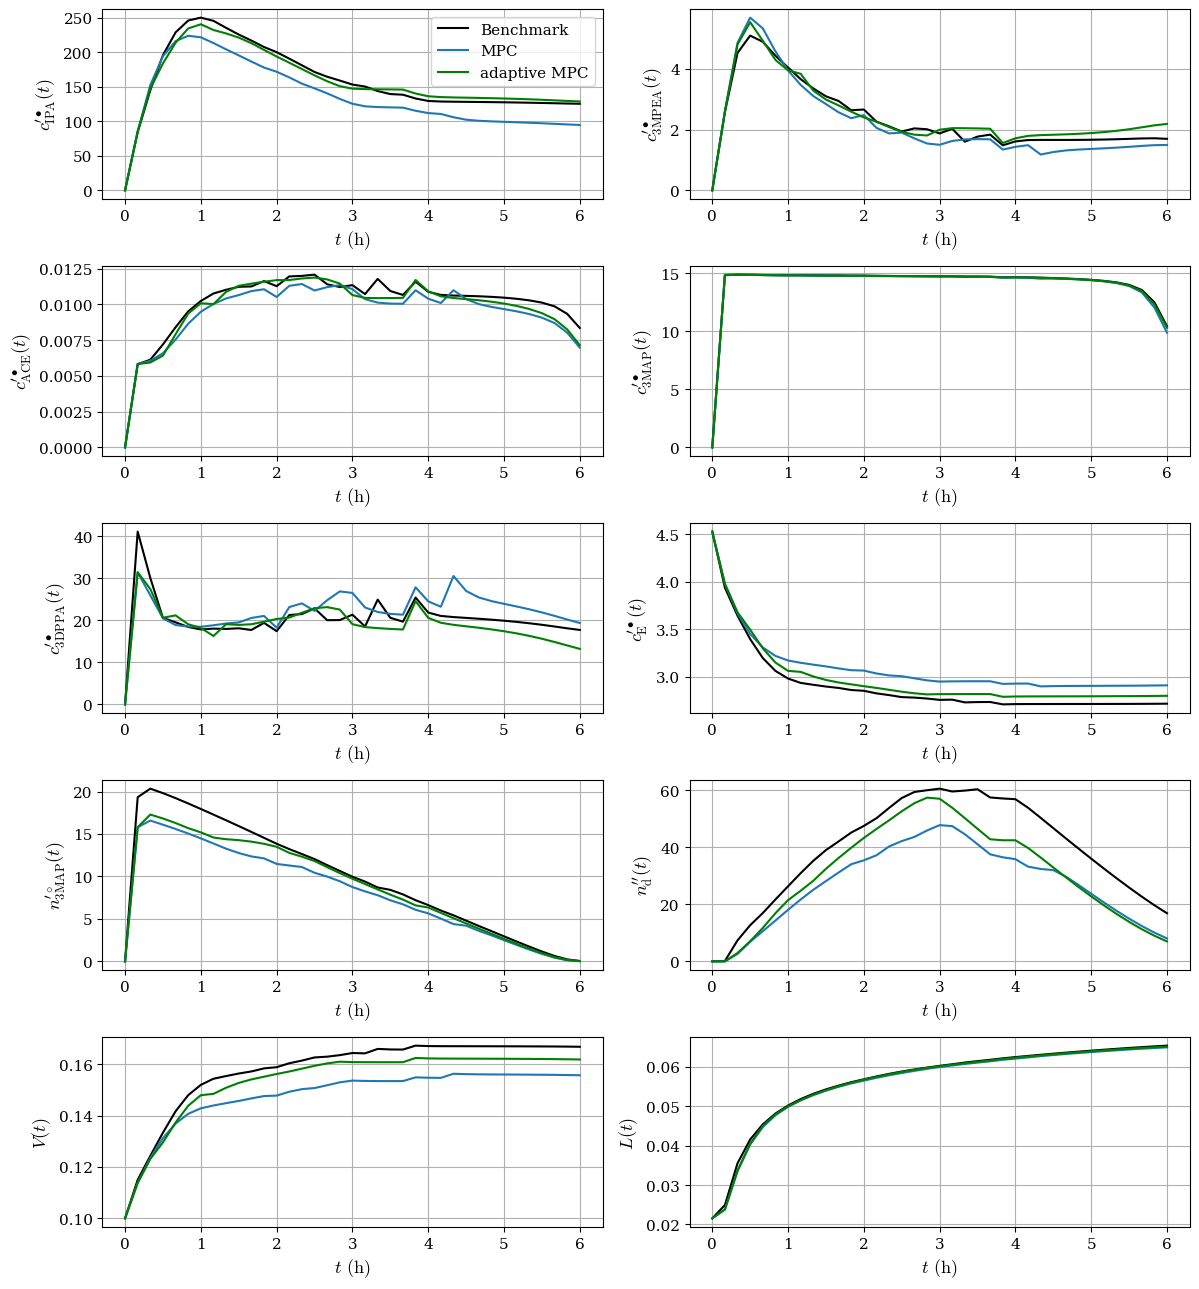

In [5]:
# get benchmark data
dataset_bench = "dataset_MPC_benchmark.npz"
data_bench = np.load(dataset_bench)
results_MPC_benchmark = {
        'X_real_tk': data_bench['X_real_tk'],
        'Y_adapted': data_bench['Y_adapted'],
        'U_applied': data_bench['U_applied']}

for i in range(n_sets):
    # Convert true crystal volume L^3 to mass in the state vector copy for plot_red_states
    x_mpc = results_MPC[i]['X_real_tk'].copy()

    x_mpc_adapted = results_MHE_MPC_PL[i]['X_real_tk'].copy()

    x_mpc_bench = results_MPC_benchmark['X_real_tk'].copy()

    plot_red_states(
        N0, p, t, 
        x_mpc, Data2=x_mpc_adapted, 
        U1=results_MPC[i]['U_applied'], U2=results_MHE_MPC_PL[i]['U_applied'], 
        label1='MPC', label2='adaptive MPC', 
        Para1=None, Para2=results_MHE_MPC_PL[i]['Para_MHE'],  # MPC has no parameter estimation, MPC_MHE has Para_MHE
        para_vals1=results_MPC[i]['p_start_log'], para_vals2=results_MHE_MPC_PL[i]['p_start_log'],
        broken_mpc1=results_MPC[i]['Broken_mpc'], broken_mpc2=results_MHE_MPC_PL[i]['Broken_mpc'],
        broken_mhe1=None, broken_mhe2=results_MHE_MPC_PL[i]['Broken_mhe'],
        Obj=results_MHE_MPC_PL[i].get('Obj_tk'), 
        Para_PL=results_MHE_MPC_PL[i].get('Para_PL'), 
        Broken_PL=results_MHE_MPC_PL[i].get('Broken_PL_tk'),
        Data_bench=x_mpc_bench, U_bench=results_MPC_benchmark['U_applied'], label_bench='Benchmark',
        save_name=f"MHE_MPC_comparison_red_nom_model{i+1}.png",
        para_plant=para_plant
    )

    plot_states_all_controls_para(
        N0, p, t, 
        x_mpc, Data2=x_mpc_adapted, 
        U1=results_MPC[i]['U_applied'], U2=results_MHE_MPC_PL[i]['U_applied'], 
        label1='MPC', label2='adaptive MPC', 
        Para1=None, Para2=results_MHE_MPC_PL[i]['Para_MHE'],  # MPC has no parameter estimation, MPC_MHE has Para_MHE
        para_vals1=results_MPC[i]['p_start_log'], para_vals2=results_MHE_MPC_PL[i]['p_start_log'],
        broken_mpc1=results_MPC[i]['Broken_mpc'], broken_mpc2=results_MHE_MPC_PL[i]['Broken_mpc'],
        broken_mhe1=None, broken_mhe2=results_MHE_MPC_PL[i]['Broken_mhe'],
        Obj=results_MHE_MPC_PL[i].get('Obj_tk'), 
        Para_PL=results_MHE_MPC_PL[i].get('Para_PL'), 
        Broken_PL=results_MHE_MPC_PL[i].get('Broken_PL_tk'),
        Data_bench=x_mpc_bench, U_bench=results_MPC_benchmark['U_applied'], label_bench='Benchmark',
        save_name=f"MHE_MPC_comparison_nom_model{i+1}.png"
    )

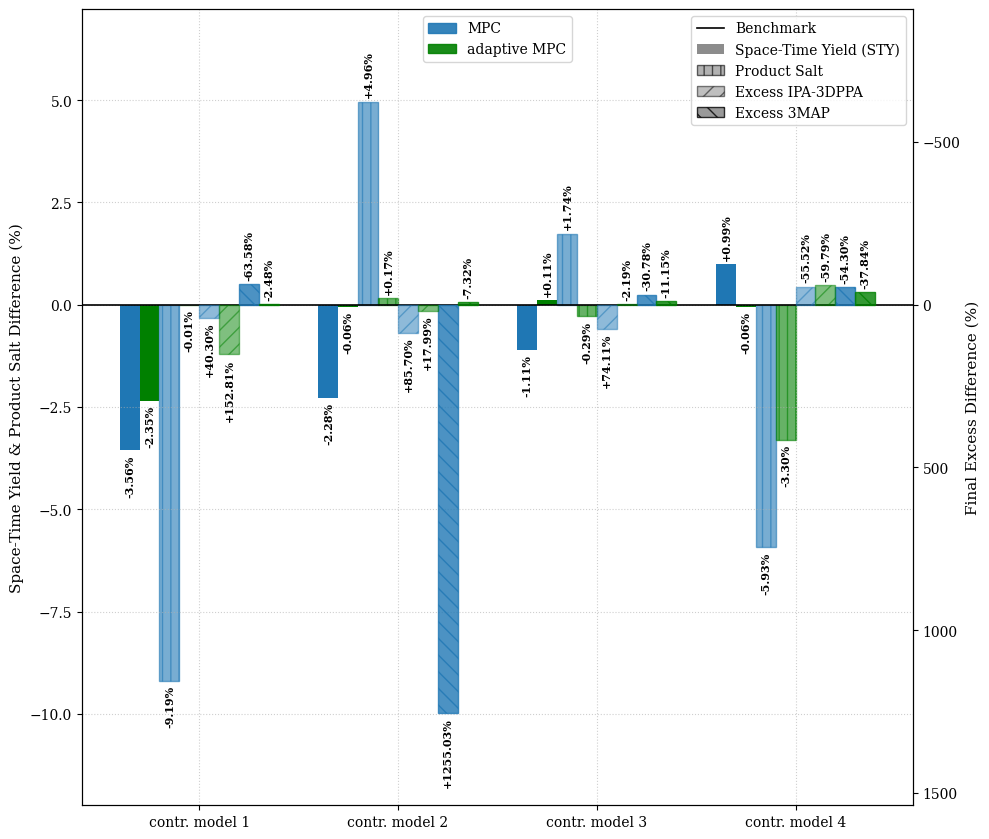

In [6]:
# 1. Ensure benchmark is loaded
import os
import numpy as np
dataset_bench = "dataset_MPC_benchmark.npz"
if not os.path.exists(dataset_bench) and os.path.exists("MPC_MHE_PL/dataset_MPC_benchmark.npz"):
    dataset_bench = "MPC_MHE_PL/dataset_MPC_benchmark.npz"
if os.path.exists(dataset_bench):
    data_bench = np.load(dataset_bench)
    results_MPC_benchmark = {
        'X_real_tk': data_bench['X_real_tk'],
        'Y_adapted': data_bench['Y_adapted'],
        'U_applied': data_bench['U_applied']
    }
else:
    raise FileNotFoundError("dataset_MPC_benchmark.npz could not be located.")

# 2. Plot percentage differences and display the table

plot_bar_difference_to_benchmark(
    N0=N0,
    p=p,
    t=t,
    molar0_seeds=molar0_seeds,
    results_MPC=results_MPC,
    results_MHE_MPC_PL=results_MHE_MPC_PL,
    results_MPC_benchmark=results_MPC_benchmark,
    save_name='MHE_MPC_comparison_bar_plot_diff.png'
)


# Perfomance table like figure above

In [7]:
import numpy as np
import os
import sys
import re

# Resolve paths
base_dir = os.path.abspath('')
dataset_bench_path = os.path.join(base_dir, "dataset_MPC_benchmark.npz")

t_span = p.tspan / 3600
data_bench = np.load(dataset_bench_path)
x_bench = data_bench['X_real_tk']

N0_val = N0.item() if hasattr(N0, 'item') else N0
sty_bench = compute_sty(x_bench, p, N0, t_span, molar0_seeds)[-1]
salt_bench = p.L_2_mass(x_bench[p.idx_L, -1], N0_val)
exc_3map_bench = x_bench[p.idx_3MAP_np, -1]
exc_ipa_bench = x_bench[p.idx_IPA_3DPPA, -1]

# --- Table 2: Performance Metrics ---
latex_perf = []
latex_perf.append(r"\begin{table*}[h]")
latex_perf.append(r"    \centering")
latex_perf.append(r"    \small")
latex_perf.append(r"    \setlength{\tabcolsep}{4pt}")
latex_perf.append(r"      \caption{Comparison of the final \ac{STY}, final amount of product salt, and final excess of \ac{3MAP} and \ac{IPA-3DPPA} for the different controller models. The total values are given together with the percentage difference with respect to the benchmark.}")
latex_perf.append(r"  \label{Tab:result percentage}") 
latex_perf.append(r" \begin{tabular}{c|c|c|c|c|c} ") 
latex_perf.append(r"  Alg. & model & \ac{STY} & $n_{\text{p}}^{\prime\prime}$ (mmol) & $n_{\text{3MAP}}^{\prime\circ}$ (mmol) & $n_{\text{d}}^{\prime\prime}$ (mmol) \\ \hline \hline")

def format_cell(val, diff, higher_is_better=True):
    if abs(diff) < 1e-9:
        return f"{val:.2f}"
    improved = (diff > 0) if higher_is_better else (diff < 0)
    color_base = "green" if improved else "red"
    intensity = min(40, max(3, int(round(4.5 * (abs(diff)**0.5)))))
    diff_str = f"{diff:+.2f}\\%"
    return f"\\cellcolor{{{color_base}!{intensity}}} {val:.2f}\\textsuperscript{{\\scriptsize {diff_str}}}"

# 1. Compute and format all values first
mpc_rows = []
mhe_rows = []
for i in range(n_sets):
    # Standard MPC
    x_mpc = results_MPC[i]['X_real_tk']
    sty_mpc = compute_sty(x_mpc, p, N0, t_span, molar0_seeds)[-1]
    salt_mpc = p.L_2_mass(x_mpc[p.idx_L, -1], N0_val)
    exc_3map_mpc = x_mpc[p.idx_3MAP_np, -1]
    exc_ipa_mpc = x_mpc[p.idx_IPA_3DPPA, -1]
    
    diff_sty_mpc = (sty_mpc - sty_bench) / sty_bench * 100
    diff_salt_mpc = (salt_mpc - salt_bench) / salt_bench * 100
    diff_exc_3map_mpc = (exc_3map_mpc - exc_3map_bench) / exc_3map_bench * 100
    diff_exc_ipa_mpc = (exc_ipa_mpc - exc_ipa_bench) / exc_ipa_bench * 100
    
    mpc_rows.append({
        'model': f"contr. model {i+1}",
        'sty': format_cell(sty_mpc, diff_sty_mpc, True),
        'salt': format_cell(salt_mpc, diff_salt_mpc, True),
        'exc_3map': format_cell(exc_3map_mpc, diff_exc_3map_mpc, False),
        'exc_ipa': format_cell(exc_ipa_mpc, diff_exc_ipa_mpc, False)
    })
    
    # Adaptive MPC 
    x_mhe = results_MHE_MPC_PL[i]['X_real_tk']
    sty_mhe = compute_sty(x_mhe, p, N0, t_span, molar0_seeds)[-1]
    salt_mhe = p.L_2_mass(x_mhe[p.idx_L, -1], N0_val)
    exc_3map_mhe = x_mhe[p.idx_3MAP_np, -1]
    exc_ipa_mhe = x_mhe[p.idx_IPA_3DPPA, -1]
    
    diff_sty_mhe = (sty_mhe - sty_bench) / sty_bench * 100
    diff_salt_mhe = (salt_mhe - salt_bench) / salt_bench * 100
    diff_exc_3map_mhe = (exc_3map_mhe - exc_3map_bench) / exc_3map_bench * 100
    diff_exc_ipa_mhe = (exc_ipa_mhe - exc_ipa_bench) / exc_ipa_bench * 100
    
    mhe_rows.append({
        'model': f"contr. model {i+1}",
        'sty': format_cell(sty_mhe, diff_sty_mhe, True),
        'salt': format_cell(salt_mhe, diff_salt_mhe, True),
        'exc_3map': format_cell(exc_3map_mhe, diff_exc_3map_mhe, False),
        'exc_ipa': format_cell(exc_ipa_mhe, diff_exc_ipa_mhe, False)
    })

# 2. Write rows to LaTeX table
# MPC group (includes plant model benchmark at the top)
latex_perf.append(f"  \\multirow{{{n_sets + 1}}}{{*}}{{\\ac{{MPC}}}} & plant model & {sty_bench:.4f} & {salt_bench:.4f} & {exc_3map_bench:.4f} & {exc_ipa_bench:.4f} \\\\ \\cline{{2-6}}") 
for idx, row in enumerate(mpc_rows):
    end_str = "\\\\ \hline" if idx == len(mpc_rows) - 1 else "\\\\ \\cline{2-6}"
    latex_perf.append(f"    & {row['model']} & {row['sty']} & {row['salt']} & {row['exc_3map']} & {row['exc_ipa']} {end_str}")

# Adaptive MPC group 
for idx, row in enumerate(mhe_rows):
    alg_cell = f"\\multirow{{{n_sets}}}{{*}}{{Adaptive \\ac{{MPC}}}}" if idx == 0 else "" 
    end_str = "\\\\ \hline" if idx == len(mhe_rows) - 1 else "\\\\ \\cline{2-6}"
    latex_perf.append(f"  {alg_cell}  & {row['model']} & {row['sty']} & {row['salt']} & {row['exc_3map']} & {row['exc_ipa']} {end_str}")

latex_perf.append(r"    \end{tabular}")
latex_perf.append(r"\end{table*}")

for folder in [base_dir, os.path.dirname(base_dir)]:
    with open(os.path.join(folder, "result_percentage_table.tex"), "w", encoding="utf-8") as f:
        f.write("\n".join(latex_perf))
print("LaTeX performance table successfully updated and written to result_percentage_table.tex!")


LaTeX performance table successfully updated and written to result_percentage_table.tex!


<>:88: SyntaxWarning: invalid escape sequence '\h'
<>:94: SyntaxWarning: invalid escape sequence '\h'
<>:88: SyntaxWarning: invalid escape sequence '\h'
<>:94: SyntaxWarning: invalid escape sequence '\h'
C:\Users\jesbehre\AppData\Local\Temp\ipykernel_28380\2405568453.py:88: SyntaxWarning: invalid escape sequence '\h'
  end_str = "\\\\ \hline" if idx == len(mpc_rows) - 1 else "\\\\ \\cline{2-6}"
C:\Users\jesbehre\AppData\Local\Temp\ipykernel_28380\2405568453.py:94: SyntaxWarning: invalid escape sequence '\h'
  end_str = "\\\\ \hline" if idx == len(mhe_rows) - 1 else "\\\\ \\cline{2-6}"


In [8]:

# Try to detect n_opt dynamically from simulation_loop.py
n_opt = 1  # default fallback
n_opt_PL = 3 

all_mpc = []
all_mhe_full = []
all_pl_full = []
all_mpc_horizons = []

# Assuming 4 nominal models
n_sets = initial_para.shape[1] 

for i in range(n_sets):
    t_mat = results_MHE_MPC_PL[i]['t_matrix'] if results_MHE_MPC_PL[i].get('t_matrix') is not None else data[f't_matrix_{i}'] 
    mpc_times = t_mat[:-1, 0]  # exclude skipped final step
    mhe_times = t_mat[:, 1]
    pl_times = t_mat[:, 2]
    
    all_mpc.append(mpc_times)
    
    # Horizons
    mpc_hors = np.array([((p.N_sample) - k) if k > 1 else N_MPC for k in range(len(mpc_times))]) 
    mhe_hors = np.array([(k + 1) if k <= N_MHE else (N_MHE + 1) for k in range(len(mhe_times))]) 
    
    full_idx = np.where(mhe_hors == N_MHE + 1)[0]
    
    all_mhe_full.append(mhe_times[full_idx])
    all_pl_full.append(pl_times[full_idx])
    all_mpc_horizons.append(mpc_hors)

pool_mpc = np.concatenate(all_mpc)
pool_mhe = np.concatenate(all_mhe_full)
pool_pl = np.concatenate(all_pl_full)
pool_mpc_hors = np.concatenate(all_mpc_horizons)

mean_mpc = np.mean(pool_mpc)
std_mpc = np.std(pool_mpc)
max_mpc_idx = np.argmax(pool_mpc)
max_mpc_val = pool_mpc[max_mpc_idx]
max_mpc_hor = pool_mpc_hors[max_mpc_idx]

mean_mhe = np.mean(pool_mhe)
std_mhe = np.std(pool_mhe)
max_mhe_val = np.max(pool_mhe)
max_mhe_hor = N_MHE + 1

mean_pl = np.mean(pool_pl)
std_pl = np.std(pool_pl)
max_pl_val = np.max(pool_pl)
max_pl_hor = N_MHE + 1

mpc_mean_str = f"{mean_mpc:.4f}~s"
mhe_mean_str = f"{mean_mhe:.4f}~s ($\pm${std_mhe:.4f}~s)"
pl_mean_str = f"{mean_pl:.4f}~s ($\pm${std_pl:.4f}~s)"

mpc_max_str = f"{max_mpc_val:.4f}~s "
mhe_max_str = f"{max_mhe_val:.4f}~s "
pl_max_str = f"{max_pl_val:.4f}~s "

# Try to load p and N_LL from the workspace, else fallback to defaults
n_p = 3
N_LL = 29
try:
    n_p = p.n_p
    N_LL = results_MHE_MPC_PL[0].get('Obj_tk').shape[2] - 1
except:
    pass

total_runs = n_p * (N_LL + 1) * n_opt_PL

latex_code = f"""\\begin{{table*}}[htbp]
    \\centering
    \\caption{{Computational time of the optimization routines over all models.  The mean computational time together with the \\ac{{STD}}, as well as the maximal computational time is given. Note that the optimization horizon for the \\ac{{MPC}} shrinks, therefore the \\ac{{STD}} is omitted. The computational time for the \\ac{{PL}} algorithm includes the calculation of \\ac{{PL}} for 40 parameter values of the three estimated parameters for 3 multi-starts  (total 360 optimization runs).}}
    \\begin{{tabular}}{{l|c|c}}
        \\hline
         \\textbf{{Algorithm}} & \\textbf{{Mean time ($\pm$\\ac{{STD}})}} & \\textbf{{Max. time }} \\\\ \\hline
         \\ac{{MPC}} &  {mpc_mean_str} & {mpc_max_str} \\\\
         \\ac{{MHE}} &  {mhe_mean_str} & {mhe_max_str} \\\\
         \\ac{{PL}}  & {pl_mean_str}  & {pl_max_str} 
    \\end{{tabular}}
    \\label{{tab:computational_times}}
\\end{{table*}}"""

print(latex_code)

\begin{table*}[htbp]
    \centering
    \caption{Computational time of the optimization routines over all models.  The mean computational time together with the \ac{STD}, as well as the maximal computational time is given. Note that the optimization horizon for the \ac{MPC} shrinks, therefore the \ac{STD} is omitted. The computational time for the \ac{PL} algorithm includes the calculation of \ac{PL} for 40 parameter values of the three estimated parameters for 3 multi-starts  (total 360 optimization runs).}
    \begin{tabular}{l|c|c}
        \hline
         \textbf{Algorithm} & \textbf{Mean time ($\pm$\ac{STD})} & \textbf{Max. time } \\ \hline
         \ac{MPC} &  0.3700~s & 9.6105~s  \\
         \ac{MHE} &  0.0485~s ($\pm$0.0161~s) & 0.0912~s  \\
         \ac{PL}  & 60.2824~s ($\pm$19.4495~s)  & 112.9988~s  
    \end{tabular}
    \label{tab:computational_times}
\end{table*}


<>:53: SyntaxWarning: invalid escape sequence '\p'
<>:54: SyntaxWarning: invalid escape sequence '\p'
<>:82: SyntaxWarning: invalid escape sequence '\p'
<>:53: SyntaxWarning: invalid escape sequence '\p'
<>:54: SyntaxWarning: invalid escape sequence '\p'
<>:82: SyntaxWarning: invalid escape sequence '\p'
C:\Users\jesbehre\AppData\Local\Temp\ipykernel_28380\426627838.py:53: SyntaxWarning: invalid escape sequence '\p'
  mhe_mean_str = f"{mean_mhe:.4f}~s ($\pm${std_mhe:.4f}~s)"
C:\Users\jesbehre\AppData\Local\Temp\ipykernel_28380\426627838.py:54: SyntaxWarning: invalid escape sequence '\p'
  pl_mean_str = f"{mean_pl:.4f}~s ($\pm${std_pl:.4f}~s)"
C:\Users\jesbehre\AppData\Local\Temp\ipykernel_28380\426627838.py:82: SyntaxWarning: invalid escape sequence '\p'
  \\end{{table*}}"""
